# Exoplanet Detection 

## Project scope

I am extending the Beginner version of this project without jumping to Random Forests.

**Scientific task:** classify Kepler Objects of Interest (KOIs) as:

- `CONFIRMED` → planet (`1`)
- `FALSE POSITIVE` → not a confirmed planet (`0`)

### Models used in this notebook

1. **Logistic Regression** —  regression-based classifier
2. **Decision Tree** — nonlinear model

### Intermediate concepts covered

- deeper EDA
- data-quality checks
- physics-informed feature engineering
- derived features
- train/test split with stratification
- preprocessing with a leakage-safe `Pipeline`
- Logistic Regression
- Decision Tree
- 5-fold Stratified Cross-Validation
- hyperparameter tuning
- multiple evaluation metrics
- ROC-AUC and Precision-Recall analysis
- model comparison
- feature interpretation
- error analysis
- SNR ablation experiment
- scientific conclusions

> **Important:** At this stage, this is **KOI classification using derived tabular Kepler features**, not raw light-curve transit detection. Raw light curves will be the Advanced stage.

## 1. Imports and Environment Setup

In [3]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

RANDOM_STATE = 42


## 2. Load the Kepler KOI Dataset

In [5]:
DATA_PATH = Path("cumulative.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Put cumulative.csv in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())


Shape: (9564, 50)


,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


## 3. Understand the Dataset

In [7]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values — top 20 columns:")
missing = df.isna().sum().sort_values(ascending=False).head(20)
display(missing.to_frame("missing_count"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
display(df["koi_disposition"].value_counts(dropna=False).to_frame("count"))


Data types:


,dtype
rowid,int64
kepid,int64
kepoi_name,object
kepler_name,object
koi_disposition,object
koi_pdisposition,object
koi_score,float64
koi_fpflag_nt,int64
koi_fpflag_ss,int64
koi_fpflag_co,int64



Missing values — top 20 columns:


,missing_count
koi_teq_err2,9564
koi_teq_err1,9564
kepler_name,7270
koi_score,1510
koi_steff_err2,483
koi_srad_err2,468
koi_srad_err1,468
koi_slogg_err2,468
koi_slogg_err1,468
koi_steff_err1,468



Duplicate rows: 0

Target distribution:


,count
koi_disposition,
FALSE POSITIVE,5023
CONFIRMED,2293
CANDIDATE,2248


### Why remove `CANDIDATE`?

For this stage we deliberately make the problem binary:

- `CONFIRMED` = `1`
- `FALSE POSITIVE` = `0`

`CANDIDATE` is not treated as a third class here because our goal is to learn a clean binary classification workflow first.

In [9]:
TARGET_MAP = {
    "CONFIRMED": 1,
    "FALSE POSITIVE": 0
}

df_clean = df[df["koi_disposition"].isin(TARGET_MAP)].copy()
df_clean["LABEL"] = df_clean["koi_disposition"].map(TARGET_MAP)

print("Filtered shape:", df_clean.shape)
display(df_clean["koi_disposition"].value_counts().to_frame("count"))


Filtered shape: (7316, 51)


,count
koi_disposition,
FALSE POSITIVE,5023
CONFIRMED,2293


## 4. Initial Feature Set

Retained physically interpretable Kepler features from the Beginner project.

| Feature | Physical meaning |
|---|---|
| `koi_period` | orbital period (days) |
| `koi_duration` | transit duration (hours) |
| `koi_depth` | transit depth (ppm) |
| `koi_model_snr` | model signal-to-noise ratio |
| `koi_steff` | stellar effective temperature (K) |
| `koi_slogg` | stellar surface gravity |
| `koi_srad` | stellar radius (solar radii) |

These are **derived/processed Kepler quantities**, so the current project is not yet raw signal detection.

In [13]:
base_features = [
    "koi_period",
    "koi_duration",
    "koi_depth",
    "koi_model_snr",
    "koi_steff",
    "koi_slogg",
    "koi_srad"
]

missing_required = [c for c in base_features if c not in df_clean.columns]
if missing_required:
    raise KeyError(f"Missing expected columns: {missing_required}")

df_clean[base_features].describe().T


,count,mean,std,min,25%,50%,75%,max
koi_period,7316.0,58.816738,121.082398,0.241843,2.237412,8.507657,36.184630,1.071233e+03
koi_duration,7316.0,5.865646,6.965178,0.104600,2.527525,3.904750,6.432175,1.385400e+02
koi_depth,7016.0,30620.113982,92873.984942,0.800000,184.550000,507.450000,2775.100000,1.541400e+06
koi_model_snr,7016.0,326.634421,891.667630,0.000000,14.700000,30.750000,123.100000,9.054700e+03
koi_steff,7016.0,5727.706813,825.221536,2661.000000,5320.000000,5779.500000,6126.000000,1.589600e+04
koi_slogg,7016.0,4.303516,0.444626,0.047000,4.206750,4.438000,4.543000,5.283000e+00
koi_srad,7016.0,1.779288,6.203126,0.116000,0.829000,1.000000,1.367000,2.299080e+02


## 5. Deeper EDA

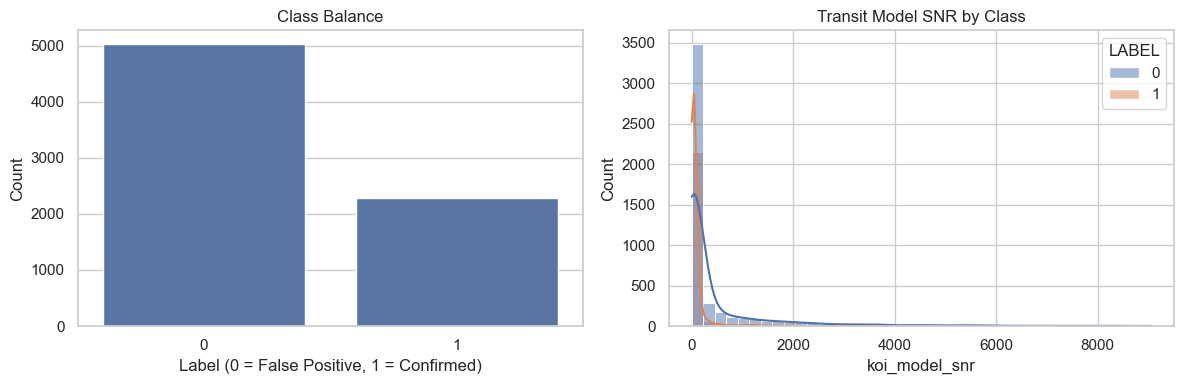

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=df_clean,
    x="LABEL",
    ax=axes[0]
)
axes[0].set_title("Class Balance")
axes[0].set_xlabel("Label (0 = False Positive, 1 = Confirmed)")
axes[0].set_ylabel("Count")

sns.histplot(
    data=df_clean,
    x="koi_model_snr",
    hue="LABEL",
    bins=40,
    kde=True,
    common_norm=False,
    ax=axes[1]
)
axes[1].set_title("Transit Model SNR by Class")
axes[1].set_xlabel("koi_model_snr")

plt.tight_layout()
plt.show()


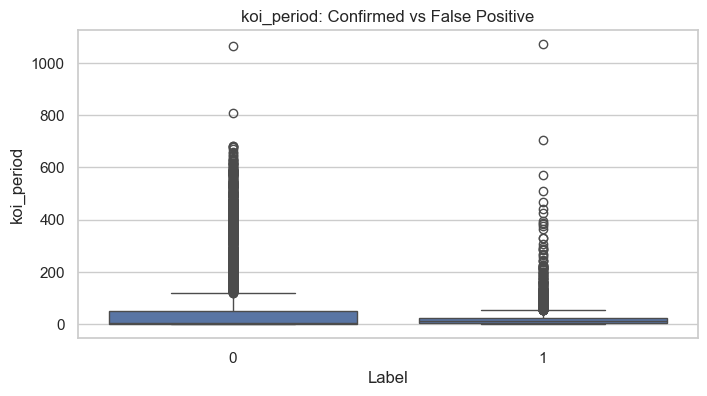

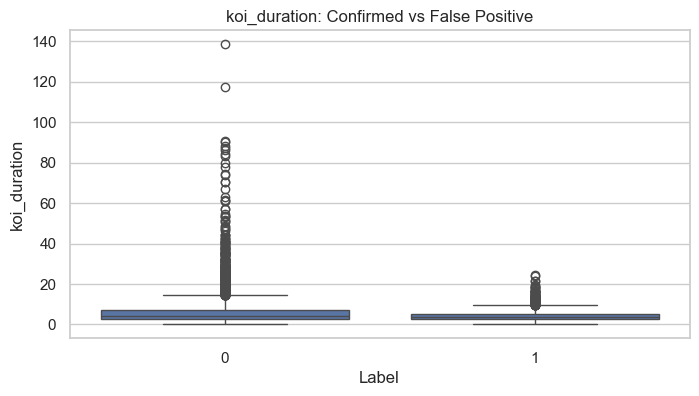

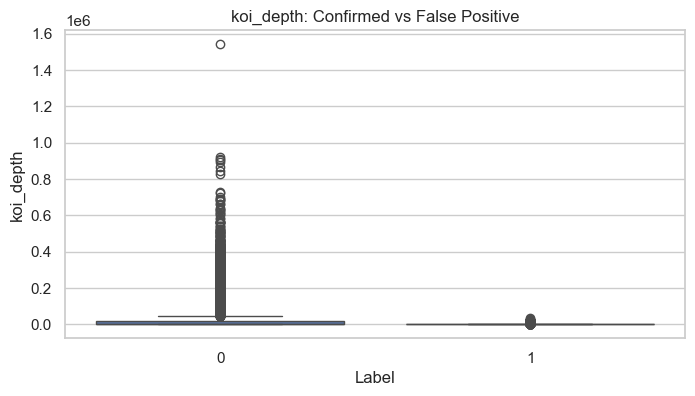

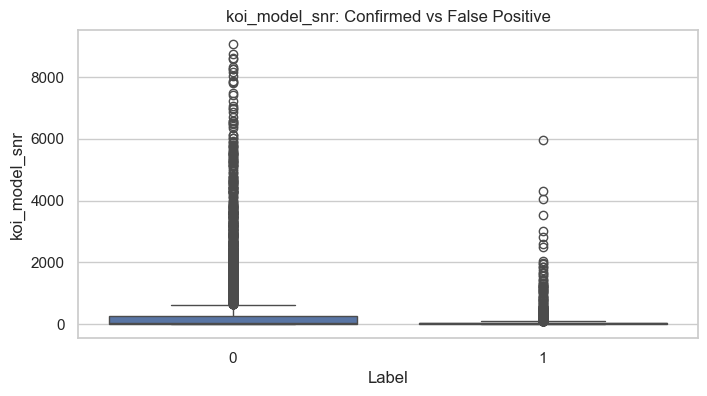

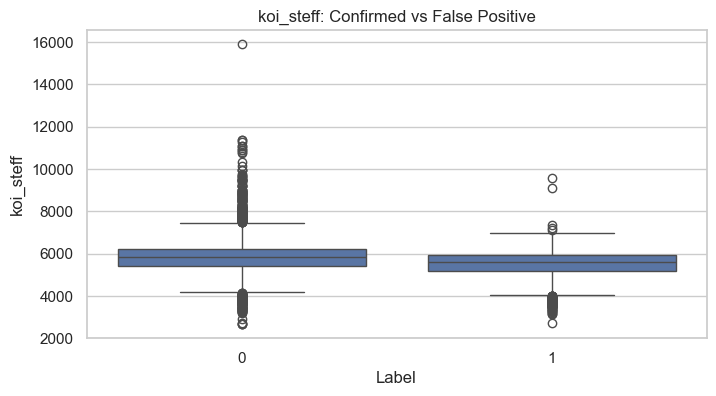

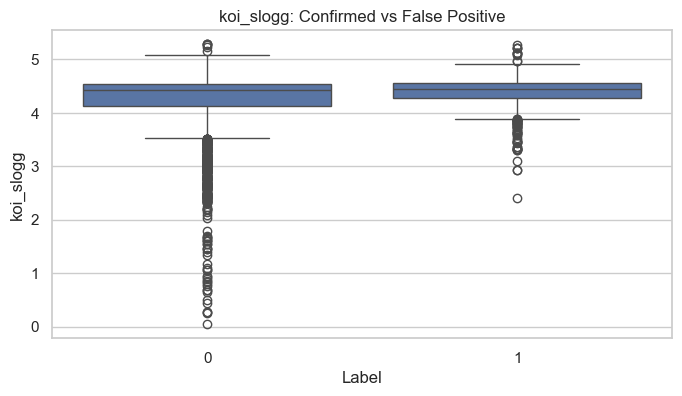

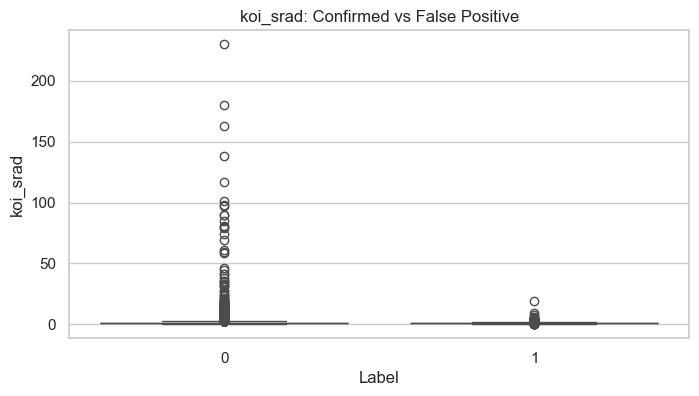

In [18]:
# Compare feature distributions by class.
eda_features = [
    "koi_period",
    "koi_duration",
    "koi_depth",
    "koi_model_snr",
    "koi_steff",
    "koi_slogg",
    "koi_srad"
]

for feature in eda_features:
    plt.figure(figsize=(8, 4))
    sns.boxplot(
        data=df_clean,
        x="LABEL",
        y=feature
    )
    plt.title(f"{feature}: Confirmed vs False Positive")
    plt.xlabel("Label")
    plt.show()


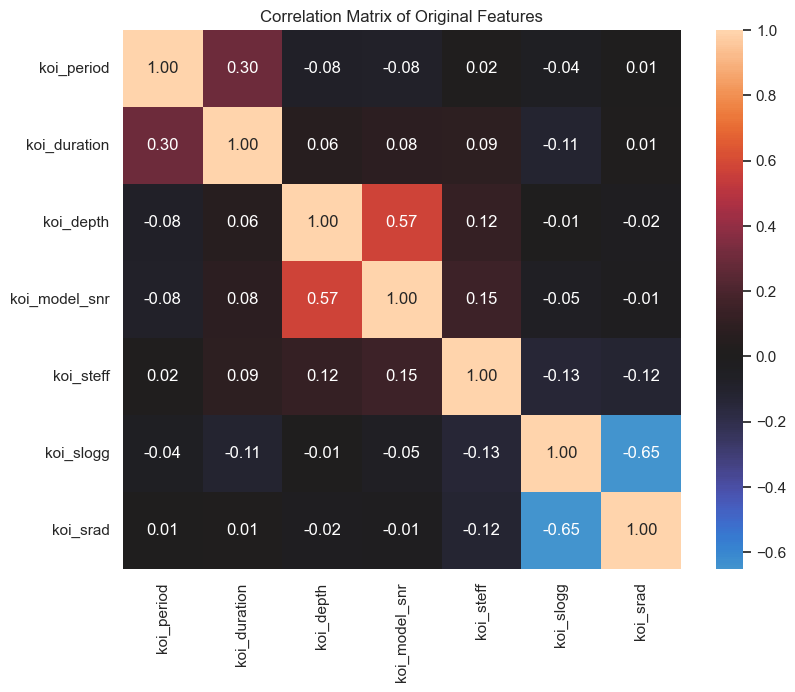

In [20]:
plt.figure(figsize=(9, 7))
corr = df_clean[base_features].corr()
sns.heatmap(corr, annot=True, fmt=".2f", center=0)
plt.title("Correlation Matrix of Original Features")
plt.show()


## 6. Physics-Informed Feature Engineering

We now create features with a physical interpretation.

### A. Transit depth as a percentage

The dataset stores transit depth in ppm:

$$ \text{depth fraction} = \frac{\text{depth ppm}}{10^6} $$

$$
\text{depth percent} = 100 \times \text{depth fraction}
$$

For a transit, approximately:

$$
\delta \approx \left(\frac{R_p}{R_s}\right)^2
$$

So transit depth carries information about the planet-to-star size ratio.

### B. Transit duty cycle

$$
D = \frac{T_{transit}}{P}
$$

Since duration is in hours and period is in days, we first convert the period to hours:

$$
D = \frac{T_{transit}}{24P}
$$

This asks: what fraction of one orbit is spent in transit?

### C. Log-transformed quantities

Period and SNR can span large ranges. We use:

$$
\log(1+x)
$$

to make the distributions easier for a linear model to work with. The transformation is applied only to non-negative quantities.

In [27]:
df_model = df_clean.copy()

df_model["transit_depth_fraction"] = df_model["koi_depth"] / 1_000_000
df_model["transit_depth_percent"] = df_model["transit_depth_fraction"] * 100

df_model["transit_duty_cycle"] = (
    df_model["koi_duration"] /
    (24 * df_model["koi_period"])
)

df_model["log_period"] = np.log1p(df_model["koi_period"])
df_model["log_snr"] = np.log1p(df_model["koi_model_snr"])

engineered_features = [
    "transit_depth_fraction",
    "transit_depth_percent",
    "transit_duty_cycle",
    "log_period",
    "log_snr"
]

features = base_features + engineered_features

display(df_model[features].describe().T)


,count,mean,std,min,25%,50%,75%,max
koi_period,7316.0,58.816738,121.082398,2.418425e-01,2.237412,8.507657,36.184630,1.071233e+03
koi_duration,7316.0,5.865646,6.965178,1.046000e-01,2.527525,3.904750,6.432175,1.385400e+02
koi_depth,7016.0,30620.113982,92873.984942,8.000000e-01,184.550000,507.450000,2775.100000,1.541400e+06
koi_model_snr,7016.0,326.634421,891.667630,0.000000e+00,14.700000,30.750000,123.100000,9.054700e+03
koi_steff,7016.0,5727.706813,825.221536,2.661000e+03,5320.000000,5779.500000,6126.000000,1.589600e+04
koi_slogg,7016.0,4.303516,0.444626,4.700000e-02,4.206750,4.438000,4.543000,5.283000e+00
koi_srad,7016.0,1.779288,6.203126,1.160000e-01,0.829000,1.000000,1.367000,2.299080e+02
transit_depth_fraction,7016.0,0.030620,0.092874,8.000000e-07,0.000185,0.000507,0.002775,1.541400e+00
transit_depth_percent,7016.0,3.062011,9.287398,8.000000e-05,0.018455,0.050745,0.277510,1.541400e+02
transit_duty_cycle,7316.0,0.048137,0.071551,5.298699e-05,0.005962,0.019173,0.059449,1.074356e+00


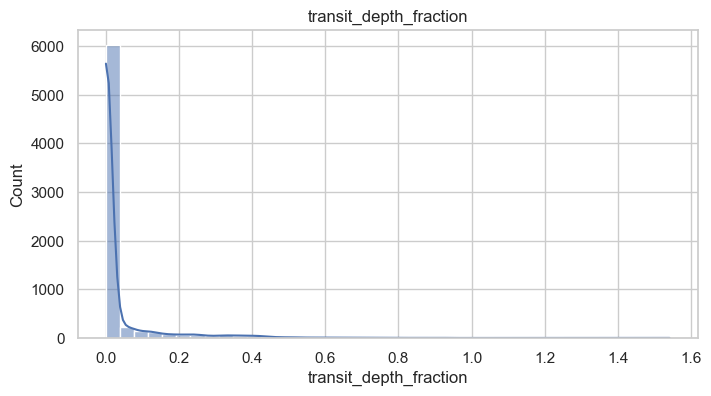

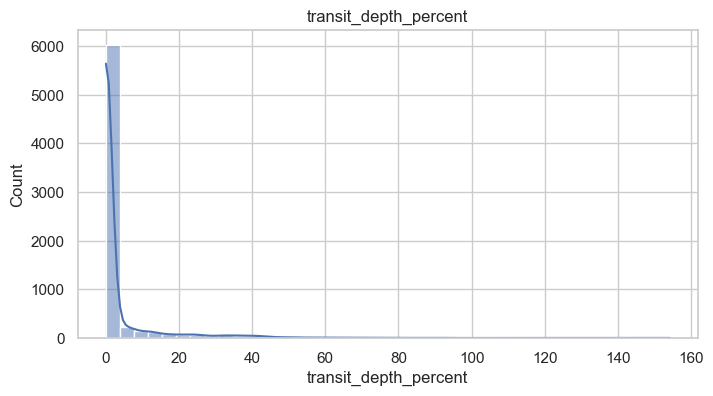

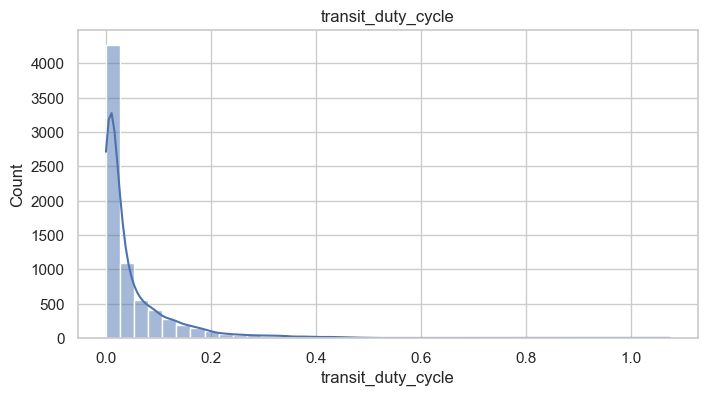

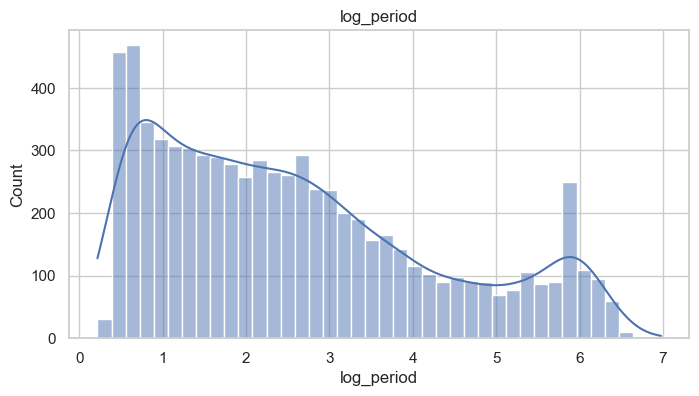

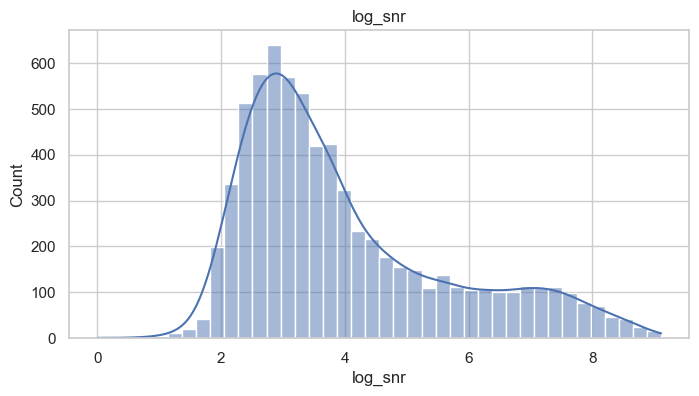

In [29]:
# Inspect the new feature distributions.
for feature in engineered_features:
    plt.figure(figsize=(8, 4))
    sns.histplot(df_model[feature].dropna(), bins=40, kde=True)
    plt.title(feature)
    plt.show()


### Important note about feature redundancy

`transit_depth_fraction` and `transit_depth_percent` contain the same information in different units. We will not assume that keeping both is useful.


## 7. Remove Impossible Values and Prepare X / y

In [32]:
# Basic domain sanity checks for quantities that should be positive.
positive_columns = [
    "koi_period",
    "koi_duration",
    "koi_depth",
    "koi_model_snr",
    "koi_steff",
    "koi_srad",
]

for col in positive_columns:
    bad = (df_model[col] <= 0).sum()
    print(f"{col}: non-positive values = {bad}")

# Keep rows where required physics quantities are valid.
valid_mask = (
    (df_model["koi_period"] > 0) &
    (df_model["koi_duration"] > 0) &
    (df_model["koi_depth"] >= 0) &
    (df_model["koi_model_snr"] >= 0) &
    (df_model["koi_steff"] > 0) &
    (df_model["koi_srad"] > 0)
)

df_model = df_model.loc[valid_mask].copy()

# Remove the duplicate-information percentage feature from the main model.
model_features = [
    "koi_period",
    "koi_duration",
    "koi_depth",
    "koi_model_snr",
    "koi_steff",
    "koi_slogg",
    "koi_srad",
    "transit_depth_fraction",
    "transit_duty_cycle",
    "log_period",
    "log_snr"
]

X = df_model[model_features]
y = df_model["LABEL"]

print("Final modeling shape:", X.shape)
print("Class balance:")
display(y.value_counts(normalize=True).rename("proportion").to_frame())


koi_period: non-positive values = 0
koi_duration: non-positive values = 0
koi_depth: non-positive values = 0
koi_model_snr: non-positive values = 1
koi_steff: non-positive values = 0
koi_srad: non-positive values = 0
Final modeling shape: (7016, 11)
Class balance:


,proportion
LABEL,
0,0.673318
1,0.326682


## 8. Train/Test Split

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())

print("\nTest class proportions:")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())


Training shape: (5612, 11)
Test shape: (1404, 11)

Training class proportions:


,proportion
LABEL,
0,0.673378
1,0.326622



Test class proportions:


,proportion
LABEL,
0,0.673077
1,0.326923


### Why stratify?

We want the train and test sets to have similar class proportions.

### Why keep the test set untouched?

The test set is our final estimate of generalization. Model selection and hyperparameter tuning should happen using the training data with cross-validation.



## 9. Baseline: Dummy Classifier

In [38]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_test)

print("Dummy Accuracy:", accuracy_score(y_test, dummy_pred))
print("Dummy Balanced Accuracy:", balanced_accuracy_score(y_test, dummy_pred))


Dummy Accuracy: 0.6730769230769231
Dummy Balanced Accuracy: 0.5


## 10. Model 1 — Logistic Regression

Logistic Regression is our improved baseline because it is:

- simple
- fast
- interpretable
- naturally probabilistic
- a useful benchmark for nonlinear models

### Important preprocessing difference

Logistic Regression is sensitive to feature scale, so we standardize the numerical features.

We use a `Pipeline` so the scaler is fitted **only on each training fold** during cross-validation.

In [42]:
logistic_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

log_cv = cross_validate(
    logistic_pipe,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

log_cv_summary = pd.DataFrame({
    "mean": {m: log_cv[f"test_{m}"].mean() for m in scoring},
    "std": {m: log_cv[f"test_{m}"].std() for m in scoring}
})

display(log_cv_summary.sort_values("mean", ascending=False))


,mean,std
roc_auc,0.912420,0.005157
accuracy,0.837310,0.007962
balanced_accuracy,0.826107,0.009025
pr_auc,0.810732,0.010304
recall,0.793785,0.018514
f1,0.761162,0.011486
precision,0.731464,0.014971


### Tune Logistic Regression

In [44]:
log_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

log_search = GridSearchCV(
    logistic_pipe,
    param_grid=log_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

log_search.fit(X_train, y_train)

print("Best Logistic Regression parameters:")
print(log_search.best_params_)
print("Best mean CV F1:", log_search.best_score_)


Best Logistic Regression parameters:
{'model__C': 100, 'model__class_weight': 'balanced'}
Best mean CV F1: 0.7770623608340463


## 11. Model 2 — Decision Tree

A Decision Tree introduces **nonlinear decision rules**.

Conceptually, the model can learn rules such as:

```text
Is SNR above a threshold?
        |
       Yes
        ↓
Is transit depth in a useful range?
        |
       Yes
        ↓
Predict Planet
```

Unlike Logistic Regression, a Decision Tree does **not require feature scaling**.

This gives us a useful experiment:

> Does a nonlinear model capture patterns that a linear model misses?

In [48]:
tree_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ))
])

tree_grid = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__max_depth": [2, 3, 4, 5, 7, 10, None],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__class_weight": [None, "balanced"]
}

tree_search = GridSearchCV(
    tree_pipe,
    param_grid=tree_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

tree_search.fit(X_train, y_train)

print("Best Decision Tree parameters:")
print(tree_search.best_params_)
print("Best mean CV F1:", tree_search.best_score_)


Best Decision Tree parameters:
{'model__class_weight': None, 'model__criterion': 'gini', 'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__min_samples_split': 10}
Best mean CV F1: 0.8141833663539625


## 12. Final Test Evaluation

In [51]:
models = {
    "Logistic Regression": log_search.best_estimator_,
    "Decision Tree": tree_search.best_estimator_
}

results = []

for name, model in models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob)
    })

results_df = pd.DataFrame(results).sort_values("F1", ascending=False)
display(results_df)


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
1,Decision Tree,0.868234,0.871304,0.756554,0.880174,0.813696,0.899826,0.775937
0,Logistic Regression,0.827635,0.852910,0.671406,0.925926,0.778388,0.917838,0.818476


### How to choose the better model

pay particular attention to:

- **Recall:** how many confirmed planets we successfully identify
- **Precision:** how many predicted planets are actually confirmed
- **F1:** balance between precision and recall
- **ROC-AUC:** ranking ability across thresholds
- **PR-AUC:** useful when positive cases are less common

The final model choice should also consider interpretability and robustness.

## 13. Confusion Matrices

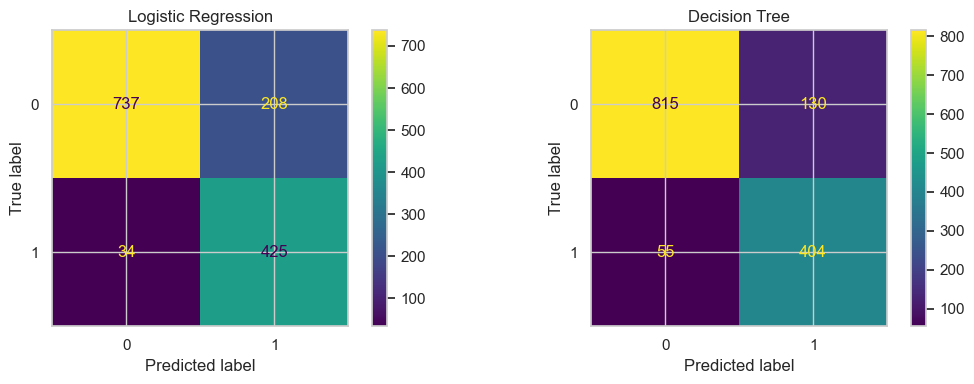

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, model) in zip(axes, models.items()):
    pred = model.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        ax=ax,
        values_format="d"
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


## 14. ROC and Precision-Recall Curves

<Figure size 800x500 with 0 Axes>

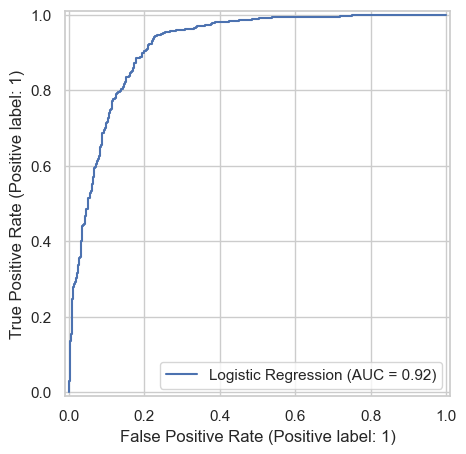

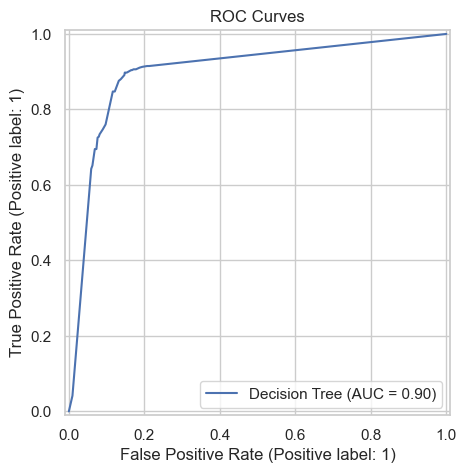

<Figure size 800x500 with 0 Axes>

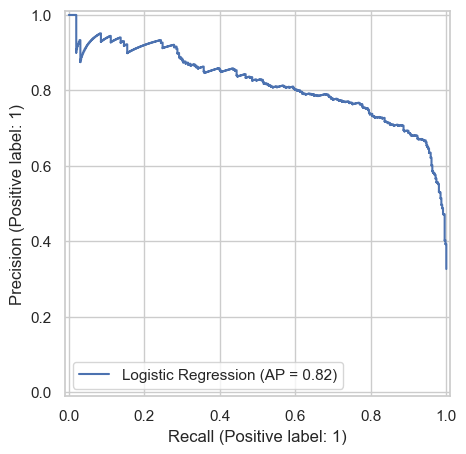

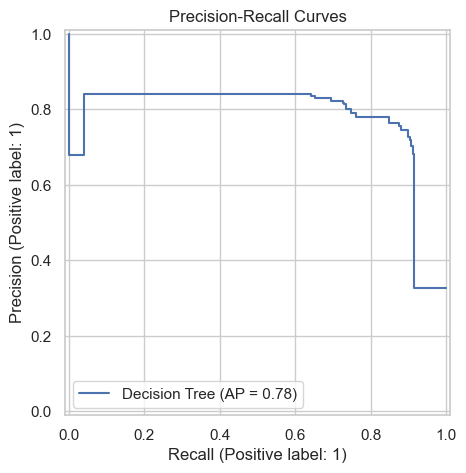

In [59]:
plt.figure(figsize=(8, 5))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name
    )

plt.title("ROC Curves")
plt.show()

plt.figure(figsize=(8, 5))

for name, model in models.items():
    PrecisionRecallDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name
    )

plt.title("Precision-Recall Curves")
plt.show()


## 15. Logistic Regression Interpretation

,Feature,Coefficient,Abs_Coefficient
7,transit_depth_fraction,-16.772779,16.772779
2,koi_depth,-16.772779,16.772779
6,koi_srad,-6.292274,6.292274
8,transit_duty_cycle,-3.642656,3.642656
10,log_snr,2.017775,2.017775
0,koi_period,-1.078433,1.078433
5,koi_slogg,-0.857021,0.857021
4,koi_steff,-0.617428,0.617428
1,koi_duration,-0.187661,0.187661
9,log_period,-0.148769,0.148769


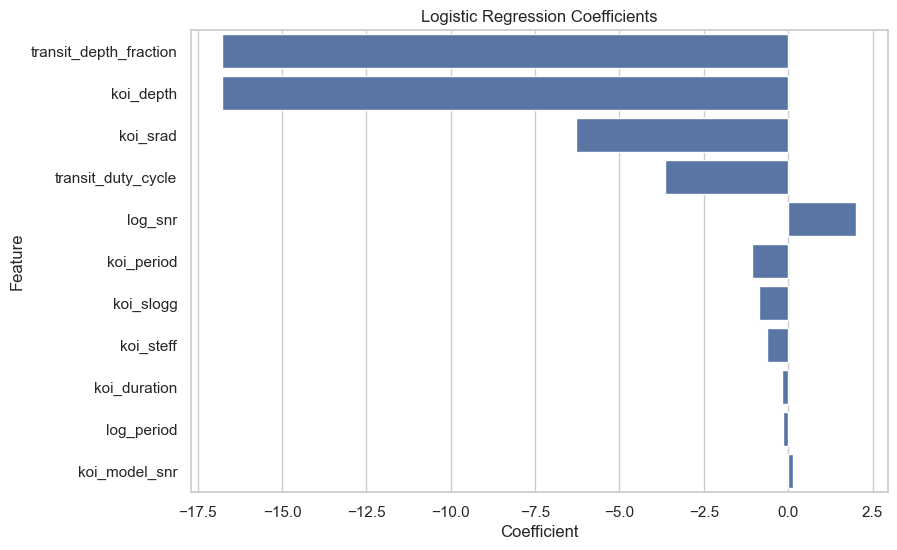

In [62]:
best_logistic = log_search.best_estimator_

feature_names = model_features
log_model = best_logistic.named_steps["model"]

log_coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": log_model.coef_[0],
    "Abs_Coefficient": np.abs(log_model.coef_[0])
}).sort_values("Abs_Coefficient", ascending=False)

display(log_coefficients)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=log_coefficients,
    x="Coefficient",
    y="Feature"
)
plt.title("Logistic Regression Coefficients")
plt.show()


### Interpreting coefficients correctly

Because Logistic Regression uses standardized features in this pipeline:

- a positive coefficient pushes the prediction toward `CONFIRMED`
- a negative coefficient pushes toward `FALSE POSITIVE`
- larger absolute values mean a stronger model association, all else equal

This is **association, not causation**.

Also remember that correlated features can share information, so coefficients should not be interpreted in isolation.

## 16. Decision Tree Interpretation

,Feature,Importance
2,koi_depth,0.267313
8,transit_duty_cycle,0.211575
3,koi_model_snr,0.177368
9,log_period,0.082666
4,koi_steff,0.053854
6,koi_srad,0.051122
1,koi_duration,0.049865
10,log_snr,0.042607
5,koi_slogg,0.022442
7,transit_depth_fraction,0.020814


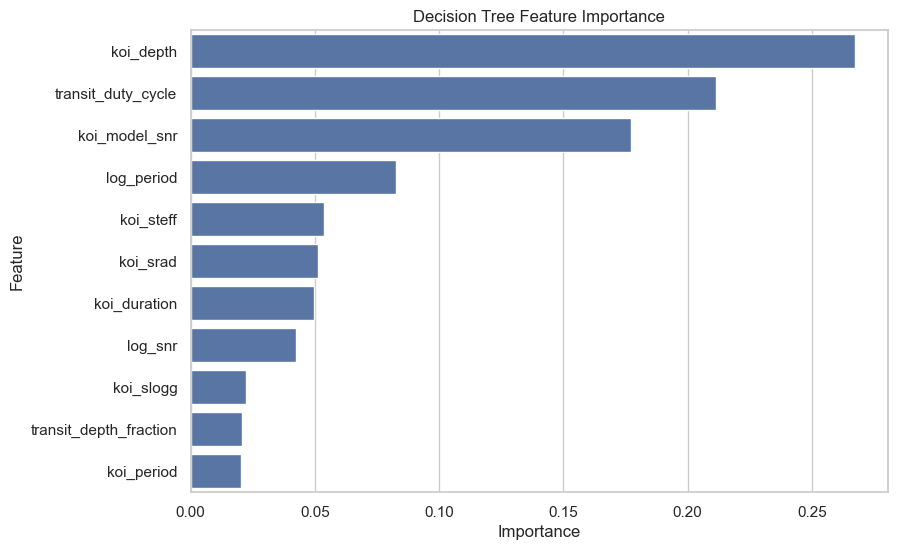

In [66]:
best_tree = tree_search.best_estimator_
tree_model = best_tree.named_steps["model"]

tree_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(tree_importance)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=tree_importance,
    x="Importance",
    y="Feature"
)
plt.title("Decision Tree Feature Importance")
plt.show()


## 17. Permutation Importance on the Test Set

In [69]:
for name, model in models.items():
    perm = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="f1",
        n_repeats=15,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    perm_df = pd.DataFrame({
        "Feature": model_features,
        "Importance_Mean": perm.importances_mean,
        "Importance_STD": perm.importances_std
    }).sort_values("Importance_Mean", ascending=False)

    print(f"\n{name}")
    display(perm_df)



Logistic Regression


,Feature,Importance_Mean,Importance_STD
8,transit_duty_cycle,0.218646,0.015739
10,log_snr,0.089836,0.009319
0,koi_period,0.087830,0.009368
2,koi_depth,0.077105,0.012034
7,transit_depth_fraction,0.077105,0.012034
6,koi_srad,0.048367,0.006274
4,koi_steff,0.019551,0.005901
5,koi_slogg,0.017669,0.004953
3,koi_model_snr,0.000250,0.001473
1,koi_duration,-0.000952,0.002836



Decision Tree


,Feature,Importance_Mean,Importance_STD
8,transit_duty_cycle,0.210638,0.016310
2,koi_depth,0.147323,0.009719
3,koi_model_snr,0.129042,0.009095
0,koi_period,0.109773,0.012209
4,koi_steff,0.063162,0.009330
6,koi_srad,0.033355,0.006809
1,koi_duration,0.032888,0.006711
9,log_period,0.028604,0.004776
7,transit_depth_fraction,0.026611,0.005270
10,log_snr,0.020211,0.004303


Permutation importance asks:

> **How much does performance deteriorate when this feature's information is randomly shuffled?**

This is a useful complement to Logistic Regression coefficients and Decision Tree impurity-based importance.

## 18. Error Analysis

In [73]:
error_analysis = X_test.copy()
error_analysis["actual"] = y_test
error_analysis["logistic_pred"] = models["Logistic Regression"].predict(X_test)
error_analysis["tree_pred"] = models["Decision Tree"].predict(X_test)

# Collect cases where the two models disagree.
disagreement = error_analysis[
    error_analysis["logistic_pred"] != error_analysis["tree_pred"]
].copy()

print("Number of model disagreements:", len(disagreement))

display(
    disagreement[
        model_features + ["actual", "logistic_pred", "tree_pred"]
    ].head(20)
)


Number of model disagreements: 185


,koi_period,koi_duration,koi_depth,koi_model_snr,koi_steff,koi_slogg,koi_srad,transit_depth_fraction,transit_duty_cycle,log_period,log_snr,actual,logistic_pred,tree_pred
5448,4.252082,2.7543,8290.5,254.8,5802.0,4.492,0.794,0.008290,0.026990,1.658625,5.544396,0,1,0
5788,2.697877,1.9150,116.8,8.3,5609.0,4.114,1.348,0.000117,0.029576,1.307759,2.230014,0,1,0
4874,14.032877,6.6840,210.9,11.8,6063.0,4.470,1.001,0.000211,0.019846,2.710240,2.549445,1,1,0
2515,2.873647,1.6820,215.7,21.2,8173.0,3.744,3.169,0.000216,0.024388,1.354196,3.100092,0,0,1
9351,4.390496,3.0112,113.5,31.1,6429.0,3.989,1.908,0.000113,0.028577,1.684637,3.468856,0,1,0
3918,6.399038,3.1500,186.6,24.1,5178.0,3.286,4.856,0.000187,0.020511,2.001350,3.222868,0,1,0
4744,30.960469,14.9920,460.9,27.1,5367.0,3.216,3.558,0.000461,0.020176,3.464500,3.335770,0,1,0
3543,1.655467,3.2424,1059.4,98.7,4583.0,4.600,0.695,0.001059,0.081608,0.976621,4.602166,0,1,0
5315,3.711012,3.3394,7559.8,257.4,6141.0,4.365,1.117,0.007560,0.037494,1.549903,5.554509,0,1,0
7048,41.865397,6.6630,4309.3,103.4,6063.0,4.584,0.788,0.004309,0.006631,3.758065,4.648230,0,1,0


### Investigate the mistakes

For each model, examine:

- false positives: predicted planet, actually false positive
- false negatives: predicted false positive, actually confirmed

Look for patterns in SNR, transit depth, duration, period, and stellar properties.

The goal is not only to ask **“How accurate is my model?”**

The better scientific question is:

> **“What kinds of systems does my model find difficult?”**

In [76]:
for name, model in models.items():
    pred = model.predict(X_test)

    fp = X_test[(y_test == 0) & (pred == 1)].copy()
    fn = X_test[(y_test == 1) & (pred == 0)].copy()

    print(f"\n{name}")
    print("False positives:", len(fp))
    print("False negatives:", len(fn))

    if len(fp) > 0:
        print("\nFalse-positive median features:")
        display(fp[model_features].median().to_frame("median"))

    if len(fn) > 0:
        print("\nFalse-negative median features:")
        display(fn[model_features].median().to_frame("median"))



Logistic Regression
False positives: 208
False negatives: 34

False-positive median features:


,median
koi_period,7.887287
koi_duration,2.942650
koi_depth,456.850000
koi_model_snr,31.100000
koi_steff,5748.000000
koi_slogg,4.468000
koi_srad,0.946500
transit_depth_fraction,0.000457
transit_duty_cycle,0.016225
log_period,2.184477



False-negative median features:


,median
koi_period,4.139810
koi_duration,3.551500
koi_depth,204.150000
koi_model_snr,21.250000
koi_steff,5853.500000
koi_slogg,4.402000
koi_srad,1.039500
transit_depth_fraction,0.000204
transit_duty_cycle,0.033373
log_period,1.636242



Decision Tree
False positives: 130
False negatives: 55

False-positive median features:


,median
koi_period,8.108109
koi_duration,3.168000
koi_depth,359.550000
koi_model_snr,23.450000
koi_steff,5762.000000
koi_slogg,4.473000
koi_srad,0.939000
transit_depth_fraction,0.000360
transit_duty_cycle,0.020052
log_period,2.208329



False-negative median features:


,median
koi_period,5.080058
koi_duration,2.777000
koi_depth,224.100000
koi_model_snr,35.300000
koi_steff,5676.000000
koi_slogg,4.440000
koi_srad,1.001000
transit_depth_fraction,0.000224
transit_duty_cycle,0.037071
log_period,1.805014


## 19. Scientific Experiment — SNR Ablation

`koi_model_snr` is a particularly informative signal-quality feature.

Instead of simply using it and reporting a high score, we test:

### Experiment A
All engineered features

### Experiment B
Remove `koi_model_snr` and `log_snr`

If the model performance drops substantially, that tells us how dependent the classifier is on a direct measure of signal quality.

This is an important scientific ML habit:

> **Test which information source is actually driving the result.**

In [80]:
no_snr_features = [
    f for f in model_features
    if f not in ["koi_model_snr", "log_snr"]
]

X_train_no_snr = X_train[no_snr_features]
X_test_no_snr = X_test[no_snr_features]

log_no_snr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

log_no_snr.fit(X_train_no_snr, y_train)
pred_no_snr = log_no_snr.predict(X_test_no_snr)
prob_no_snr = log_no_snr.predict_proba(X_test_no_snr)[:, 1]

snr_ablation = pd.DataFrame([
    {
        "Experiment": "Logistic Regression — with SNR",
        "F1": f1_score(y_test, models["Logistic Regression"].predict(X_test)),
        "ROC-AUC": roc_auc_score(
            y_test,
            models["Logistic Regression"].predict_proba(X_test)[:, 1]
        )
    },
    {
        "Experiment": "Logistic Regression — without SNR",
        "F1": f1_score(y_test, pred_no_snr),
        "ROC-AUC": roc_auc_score(y_test, prob_no_snr)
    }
])

display(snr_ablation)


,Experiment,F1,ROC-AUC
0,Logistic Regression — with SNR,0.778388,0.917838
1,Logistic Regression — without SNR,0.750751,0.890973


## 20. Visualize a Shallow Decision Tree

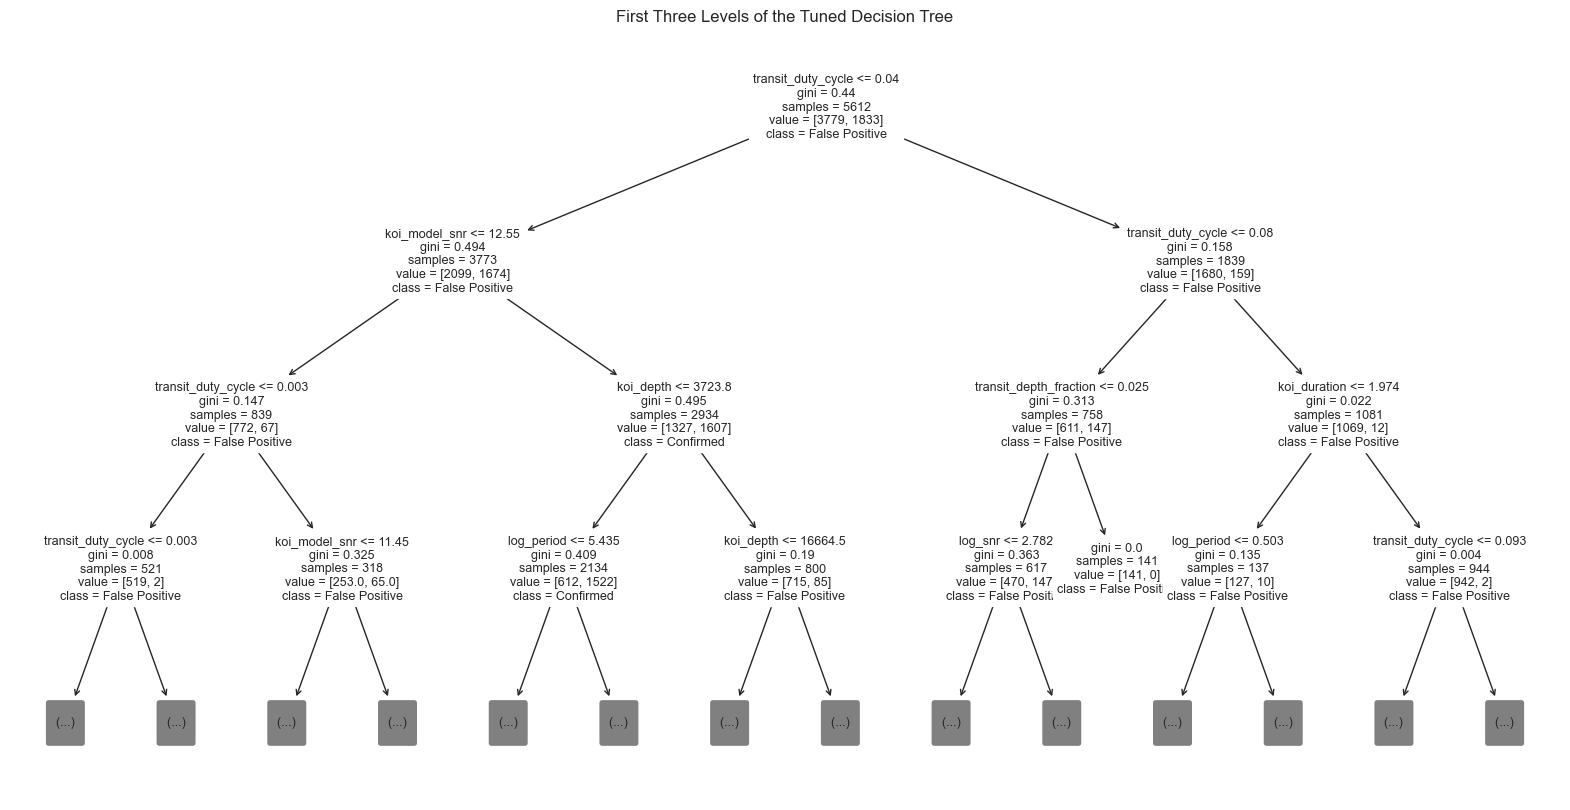

In [88]:
plt.figure(figsize=(20, 10))

plot_tree(
    tree_model,
    feature_names=model_features,
    class_names=["False Positive", "Confirmed"],
    filled=False,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("First Three Levels of the Tuned Decision Tree")
plt.show()


## 21. Final Model Comparison

In [90]:
final_comparison = results_df.copy()

display(
    final_comparison[
        [
            "Model",
            "Accuracy",
            "Balanced Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "PR-AUC"
        ]
    ]
)


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
1,Decision Tree,0.868234,0.871304,0.756554,0.880174,0.813696,0.899826,0.775937
0,Logistic Regression,0.827635,0.852910,0.671406,0.925926,0.778388,0.917838,0.818476
